# Uncertainty-aware receiver design for ground-to-air FSO links

**Nishat Yasmin Anika** · [Google Scholar](https://scholar.google.com/citations?hl=en&user=K0-97vkAAAAJ)  
**Research notebook · 1550 nm illustrative optical-link study**

This notebook contains the source files, numerical checks, simulations and reproducible figures for the [GitHub project](../README.md). It studies **layered atmospheric loss**, **Gaussian-beam aperture capture**, **pointing jitter** and **receiver-size sensitivity** to uncertain weather-scenario frequencies.

**Read before interpretation:** hardware and across-scenario weather probabilities are illustrative, and the published source's attenuation coefficient convention is ambiguous. Both readings are evaluated in the study. This is a received-power availability model, **not** measured link performance or a complete BER model.


## 1. Research question

How much receiver-aperture diameter is required to reach a target optical-power availability when pointing accuracy and the relative frequencies of weather scenarios are uncertain?

We calculate conditional availability using the circular-aperture Gaussian beam model and zero-mean pointing jitter. The minimum-aperture design considers uncertainty in the scenario mixture through total-variation distance. Numerical quadrature, linear programming, and Monte Carlo simulation provide independent checks.

Abbreviations: FSO = free-space optical; UAV = unmanned aerial vehicle; HAPS = high-altitude platform station; CDF = cumulative distribution function; TV = total variation; MC = Monte Carlo; LP = linear programming; BER = bit error rate; SD = standard deviation; dB = decibel; µrad = microradian.


## 2. Model in six equations

Let $H$ be platform altitude, $\zeta$ zenith angle and $L=H/\cos\zeta$ the slant path. Published piecewise coefficients give $T_{\rm atm}$ by layer [source, Section III].

For a receiver-plane 2D Gaussian irradiance of $1/e^2$ radius $w$, the captured fraction for an aperture radius $a$ at beam displacement $r$ equals

$$
G(a,r,w)=F_{\chi'^2_2(\lambda)}((2a/w)^2),\qquad \lambda=(2r/w)^2.
$$

Two zero-mean independent transverse pointing errors with per-axis angular SD $\sigma_\theta$ imply $R\sim\mathrm{Rayleigh}(L\sigma_\theta)$. Received optical power is

$$
P_{\rm rx}=P_{\rm tx}\,\eta_{\rm opt}\,T_{\rm atm}\,G(a,R,w).
$$

We define power availability $A=\Pr(P_{\rm rx}\ge P_{\min})$, **not BER or true network outage**. Invert $G$ to obtain the critical radial displacement $r_*$, then compute exact conditional probability:

$$
\Pr(\mathrm{success}\mid T)=1-\exp\left[-\frac{r_*^2}{2(L\sigma_\theta)^2}\right].
$$

Across five weather categories with a **hypothetical** nominal prior $q$, the *worst-case* weather mix belongs to a TV ambiguity ball

$$
\mathcal U(q,\rho)=\{p:\ p\ge0,\ \mathbf1^T p=1,\ \frac12\|p-q\|_1\le\rho\}.
$$

The design solves

$$
a^*(\rho,\sigma_\theta)=\min\{a:\ \min_{p\in\mathcal U(q,\rho)}\sum_s p_s A_s(a,\sigma_\theta)\ge A_{\rm target}\}.
$$

The worst-case expectation is solved by a probability-mass-transfer algorithm and checked against **HiGHS LP**. The outer aperture calculation uses the **Brent–Dekker root method**; both are exact up to numerical tolerances under the model.


In [1]:
# Preparation: standard Google Colab CPU libraries are usually pre-installed.
# Install only if a required library is missing (no fixed network operation if installed).
import importlib.util, subprocess, sys, time
missing = [p for p in ('numpy','scipy','matplotlib') if importlib.util.find_spec(p) is None]
if missing:
    subprocess.check_call([sys.executable, '-m','pip','install','numpy>=1.24,<3','scipy>=1.11,<2','matplotlib>=3.7,<4'])
from pathlib import Path
Path('src').mkdir(exist_ok=True)
Path('tests').mkdir(exist_ok=True)
Path('results').mkdir(exist_ok=True)
print('Dependency check passed; missing packages installed:', missing)


Dependency check passed; missing packages installed: []


## 3. Embedded source files — transparent and directly portable to GitHub

The cells below write the **exact same Python source files included in the repository**. The notebook works without cloning GitHub and without downloading a second archive. The functions themselves remain readable Python. Run all cells top to bottom.


### Published 1550-nm layered atmosphere

Writes `src/atmosphere.py` to the temporary Colab working directory.

In [2]:
%%writefile src/atmosphere.py
"""Transparent 1550-nm atmospheric-only FSO simulation.

Numerical coefficients: Erdogan et al. (2026), IEEE Vehicular Technology
Magazine, Table I/II. Paper: https://doi.org/10.1109/MVT.2026.3687349

Important unit ambiguity: Table I reports dB/km but Eqs. (1)-(3) insert
coefficients directly into exp(-sum coefficient * path). We therefore support
T = exp(-Q) ('paper_exponential') and T = 10**(-Q/10) ('db_label').
Neither interpretation is claimed to be independently physically validated.
"""
from __future__ import annotations
from dataclasses import dataclass
from itertools import product
from math import cos, exp, isclose, isfinite, log, radians, sqrt
import numpy as np

PAPER_EXPONENTIAL = 'paper_exponential'
DB_LABEL = 'db_label'
CONVENTIONS = (PAPER_EXPONENTIAL, DB_LABEL)
WAVELENGTH_NM = 1550
MAX_ZENITH_DEG = 70.0


@dataclass(frozen=True)
class State:
    name: str
    probability: float
    printed_coefficient_per_km: float

    def __post_init__(self):
        if not (isfinite(self.probability) and 0 <= self.probability <= 1):
            raise ValueError('State probability must be finite and in [0,1]')
        if not (isfinite(self.printed_coefficient_per_km)
                and self.printed_coefficient_per_km >= 0):
            raise ValueError('Coefficient must be nonnegative and finite')


@dataclass(frozen=True)
class Layer:
    name: str
    bottom_km: float
    top_km: float
    states: tuple[State, ...]

    def __post_init__(self):
        if not (isfinite(self.bottom_km) and isfinite(self.top_km)
                and 0 <= self.bottom_km < self.top_km):
            raise ValueError('Layer boundaries must be ordered, finite, nonnegative')
        if not self.states or not isclose(sum(s.probability for s in self.states), 1.0,
                                          rel_tol=0, abs_tol=1e-11):
            raise ValueError('Mutually exclusive layer-state probabilities must sum to 1')


@dataclass(frozen=True)
class Scenario:
    name: str
    layers: tuple[Layer, ...]

    def __post_init__(self):
        if not self.layers or self.layers[0].bottom_km != 0:
            raise ValueError('Scenarios must start at ground level')
        for left, right in zip(self.layers[:-1], self.layers[1:]):
            if not isclose(left.top_km, right.bottom_km, abs_tol=1e-11):
                raise ValueError('Layers must be contiguous without overlaps or gaps')

    @property
    def top_km(self) -> float:
        return self.layers[-1].top_km


def _slab(name: str, lower: float, upper: float,
          *states: tuple[str, float, float]) -> Layer:
    return Layer(name, lower, upper, tuple(State(*x) for x in states))


def scenarios_1550nm() -> dict[str, Scenario]:
    """Transcription of Table II, with rainy clear-air 14.2 km split around cloud.

    Table II prints coefficients as dB/km, but Eqs. 1-3 use exp(-coefficient*km).
    The five *conditional* scenarios are not assigned probabilities relative
    to each other. Within a slab, probabilities apply to mutually exclusive states.
    """
    clear = ('clear air', 1.0, 0.0025)
    volcanic = _slab('stratospheric volcanic aerosol', 15, 30,
                     ('high volcanic activity', .5, .0104),
                     ('background volcanic activity', .5, .0002036))
    return {
        'rain': Scenario('Rain / nimbostratus', (
            _slab('lower clear air', 0, .6, clear),
            _slab('nimbostratus cloud', .6, 1.4,
                  ('nimbostratus', .9, 8.2425), ('normal air', .1, .034)),
            _slab('upper clear air', 1.4, 15, clear), volcanic)),
        'fog': Scenario('Two-layer fog', (
            _slab('thick fog', 0, 1, ('thick fog', 1, 1.7680)),
            _slab('light fog', 1, 2, ('light fog', 1, .4592)),
            _slab('upper clear air', 2, 15, clear), volcanic)),
        'clear': Scenario('Clear atmosphere', (
            _slab('normal lower air', 0, 3, ('normal air', 1, .034)),
            _slab('upper clear air', 3, 15, clear), volcanic)),
        'pollution': Scenario('Extreme air pollution', (
            _slab('mixed urban aerosol', 0, 3,
                  ('extremely polluted', .7, .3536), ('normal air', .3, .034)),
            _slab('upper clear air', 3, 15, clear), volcanic)),
        'snow': Scenario('Heavy snow', (
            _slab('heavy snow', 0, 2, ('heavy snow', 1, .2)),
            _slab('upper clear air', 2, 15, clear), volcanic)),
    }


def path_lengths_km(scenario: Scenario, altitude_km: float,
                    zenith_deg: float = 0) -> np.ndarray:
    """Flat, horizontal slab intersection. Zenith = angle from local vertical."""
    if not (isfinite(altitude_km) and 0 <= altitude_km <= scenario.top_km):
        raise ValueError(f'Altitude must be 0 to {scenario.top_km} km')
    if not (isfinite(zenith_deg) and 0 <= zenith_deg <= MAX_ZENITH_DEG):
        raise ValueError(f'Zenith must be 0 to {MAX_ZENITH_DEG} degrees')
    secant = 1.0 / cos(radians(zenith_deg))
    return np.array([max(0., min(altitude_km, l.top_km) - l.bottom_km) * secant
                     for l in scenario.layers], dtype=float)


def integrated_printed_coefficient(scenario: Scenario, altitude_km: float,
                                   zenith_deg: float = 0) -> float:
    """Q = sum(d_j*sum_k(p_jk*c_jk)); dimension depends on interpretation."""
    ds = path_lengths_km(scenario, altitude_km, zenith_deg)
    return float(sum(d*sum(s.probability*s.printed_coefficient_per_km for s in layer.states)
                     for d, layer in zip(ds, scenario.layers)))


def transmittance_from_q(q: float | np.ndarray,
                         convention: str = PAPER_EXPONENTIAL):
    """Two explicitly separate readings of the source's coefficient notation."""
    if convention not in CONVENTIONS:
        raise ValueError(f'Unknown convention {convention!r}')
    q = np.asarray(q, dtype=float)
    if np.any(~np.isfinite(q)) or np.any(q < 0):
        raise ValueError('Q must be finite and nonnegative')
    val = np.exp(-q) if convention == PAPER_EXPONENTIAL else np.power(10., -q/10.)
    return float(val) if val.ndim == 0 else val


def loss_db_from_q(q: float | np.ndarray,
                   convention: str = PAPER_EXPONENTIAL):
    """Equivalent power loss in dB, *after* choosing a convention."""
    if convention not in CONVENTIONS:
        raise ValueError('Unknown convention')
    return np.asarray(q) * (10. / log(10.) if convention == PAPER_EXPONENTIAL else 1.)


def effective_transmittance(scenario: Scenario, altitude_km: float,
                            zenith_deg: float = 0,
                            convention: str = PAPER_EXPONENTIAL) -> float:
    """T_eff = f(E[Q]); *not* generally equal to E[f(Q)]."""
    return transmittance_from_q(integrated_printed_coefficient(
        scenario, altitude_km, zenith_deg), convention)


def exact_distribution(scenario: Scenario, altitude_km: float,
                       zenith_deg: float = 0) -> tuple[np.ndarray, np.ndarray]:
    """Enumerate independent per-layer categorical states (at most 4 here).

    Returns Q values and their probabilities. Independence is an explicit
    teaching assumption, NOT a weather-correlation estimate from ERA5.
    Complexity O(N_layers * product_j K_j); suitable ONLY for few states.
    """
    ds = path_lengths_km(scenario, altitude_km, zenith_deg)
    active = [(l, d) for l, d in zip(scenario.layers, ds) if d > 0]
    if not active:
        return np.array([0.]), np.array([1.])
    q_values, probabilities = [], []
    for selected in product(*(layer.states for layer, _ in active)):
        q_values.append(sum(state.printed_coefficient_per_km*d
                            for state, (_, d) in zip(selected, active)))
        probabilities.append(float(np.prod([s.probability for s in selected])))
    probs = np.asarray(probabilities, dtype=float)
    if not np.isclose(probs.sum(), 1.0, atol=1e-12):
        raise RuntimeError('Enumeration probabilities do not normalize')
    return np.asarray(q_values, dtype=float), probs


def exact_statistics(scenario: Scenario, altitude_km: float,
                     zenith_deg: float = 0, budget_db: float = 3.,
                     convention: str = PAPER_EXPONENTIAL) -> dict[str, float]:
    """Exact finite-state E[T] and atmospheric loss-budget exceedance.

    Budget exceedance is NOT receiver outage: receiver, scintillation,
    pointing loss, geometric spread, photodetector noise are absent.
    """
    if not (isfinite(budget_db) and budget_db >= 0):
        raise ValueError('Budget must be finite and nonnegative')
    q, p = exact_distribution(scenario, altitude_km, zenith_deg)
    t = transmittance_from_q(q, convention)
    return {'mean_q': float(np.dot(p, q)),
            'effective_transmittance': effective_transmittance(
                scenario, altitude_km, zenith_deg, convention),
            'mean_transmittance': float(np.dot(p, t)),
            'exceedance_probability': float(np.dot(p, loss_db_from_q(q, convention) > budget_db)),
            'number_of_combinations': len(q)}


def mean_transmittance_factorized(scenario: Scenario, altitude_km: float,
                                  zenith_deg: float = 0,
                                  convention: str = PAPER_EXPONENTIAL) -> float:
    """O(sum K_j) analytic E[T] if states in different slabs are independent."""
    ds = path_lengths_km(scenario, altitude_km, zenith_deg)
    product_mean = 1.
    for l, d in zip(scenario.layers, ds):
        product_mean *= sum(s.probability * transmittance_from_q(
            s.printed_coefficient_per_km*d, convention) for s in l.states)
    return float(product_mean)


def sample_q(scenario: Scenario, altitude_km: float, zenith_deg: float = 0,
             n: int = 10000, seed: int = 20261123) -> np.ndarray:
    """Vectorized categorical Monte Carlo (MC), only for cross-checking."""
    if not isinstance(n, (int, np.integer)) or n < 1:
        raise ValueError('Sample count must be positive integer')
    ds = path_lengths_km(scenario, altitude_km, zenith_deg)
    rng = np.random.default_rng(seed)  # PCG64 as currently selected by NumPy default_rng
    total = np.zeros(n, dtype=float)
    for l, d in zip(scenario.layers, ds):
        if d == 0:
            continue
        coeffs = np.array([s.printed_coefficient_per_km for s in l.states])
        probs = np.array([s.probability for s in l.states])
        total += rng.choice(coeffs, size=n, p=probs) * d
    return total


def wilson_interval(successes: int, n: int, z: float = 1.959963984540054):
    """Wilson score interval for Bernoulli trials, approximately 95% for z=1.96."""
    if n < 1 or not 0 <= successes <= n:
        raise ValueError('Invalid count')
    p = successes / n
    denom = 1 + z*z/n
    center = (p + z*z/(2*n))/denom
    half = z * sqrt(p*(1-p)/n + z*z/(4*n*n))/denom
    return max(0., center-half), min(1., center+half)


def uniform_ground_baseline_q(scenario: Scenario, altitude_km: float,
                              zenith_deg: float = 0) -> float:
    """Deliberately naive surface-only baseline; NOT another published model."""
    path_lengths_km(scenario, altitude_km, zenith_deg)
    bottom = scenario.layers[0]
    ground_coefficient = sum(s.probability*s.printed_coefficient_per_km
                             for s in bottom.states)
    return ground_coefficient*altitude_km/cos(radians(zenith_deg))


Writing src/atmosphere.py


### Exact optical-link and robust-design methods

Writes `src/fso_link.py` to the temporary Colab working directory.

In [3]:
%%writefile src/fso_link.py
"""Illustrative ground-to-air FSO link design model.

Model components:
* atmosphere.py transcribes Erdogan et al. (2026) Tables I-II with dual-unit audit
* circular-aperture capture fraction for an offset isotropic 2D Gaussian beam
* independent, zero-mean Gaussian horizontal/vertical pointing-jitter components
* conditional exact optical-power availability (weather mixture, Rayleigh jitter)
* worst-case probability under total-variation (TV) distance <= rho from a nominal
  **illustrative**, not empirically estimated, weather-scenario mixture.

This is not a complete end-to-end communications BER/outage model: atmospheric
scintillation, turbulence fading, pointing temporal dynamics, noise and detector
thermal effects are excluded, and sensitivity is a demonstration threshold.
"""
from __future__ import annotations
from dataclasses import dataclass, asdict
import math
from typing import Dict
import numpy as np
from scipy.stats import ncx2
from scipy.optimize import brentq, linprog
from scipy.integrate import quad
from scipy.special import i0e
from atmosphere import (PAPER_EXPONENTIAL, DB_LABEL, scenarios_1550nm,
                        exact_distribution, transmittance_from_q)

SCENARIO_NAMES = ('clear','pollution','fog','rain','snow')
# Hypothetical demonstration mixture, NOT ERA5-derived; source paper does
# NOT provide a probability distribution across the five weather scenarios.
DEFAULT_PRIOR = np.array([.76, .10, .07, .04, .03])

@dataclass(frozen=True)
class Link:
    altitude_km: float = 3.0
    zenith_deg: float = 0.0
    tx_mw: float = 50.0
    optical_efficiency: float = 0.70
    threshold_mw: float = 2.0
    beam_waist_m: float = .025
    divergence_urad: float = 55.0
    convention: str = PAPER_EXPONENTIAL

    def __post_init__(self):
        for name in ('altitude_km','tx_mw','optical_efficiency','threshold_mw','beam_waist_m','divergence_urad'):
            x = getattr(self, name)
            if not np.isfinite(x) or x <= 0:
                raise ValueError(f'{name} must be positive and finite')
        if not (0 < self.optical_efficiency <= 1):
            raise ValueError('optical efficiency outside (0,1]')
        if not (0 <= self.zenith_deg < 70):
            raise ValueError('Zenith out of range')
        if self.convention not in (PAPER_EXPONENTIAL,DB_LABEL):
            raise ValueError('Unknown atmospheric convention')
        if self.altitude_km > 30:
            raise ValueError('Source scenarios terminate at 30 km')

    @property
    def length_m(self):
        # Flat Earth and parallel horizontal layers as in atmospheric slab model
        return 1000 * self.altitude_km / math.cos(math.radians(self.zenith_deg))

    @property
    def beam_radius_m(self):
        # Simplified far-field Gaussian 1/e^2 intensity radius; **not** a
        # diffraction-limited propagation calculation, beam waist/divergence
        # are independent illustrative inputs.
        return math.hypot(self.beam_waist_m, self.divergence_urad*1e-6*self.length_m)


def gaussian_aperture_capture(a_m: float, w_m: float, displacement_m):
    """Exact integral of 2-D normalized Gaussian intensity over circular aperture.

    I(x,y) = 2/(pi*w^2) exp(-2*||[x,y]-[r,0]||^2/w^2).
    Integrated power = F_{noncentral chi-square(2, lambda)}((2a/w)^2),
    lambda=(2r/w)^2. This is geometrical+pointing collection only.
    """
    if a_m <= 0 or w_m <= 0:
        raise ValueError('Aperture radius and beam radius must be positive')
    r = np.asarray(displacement_m)
    if np.any(r < 0):
        raise ValueError('Displacement must be >=0')
    x = (2*a_m/w_m)**2
    return ncx2.cdf(x, df=2, nc=(2*r/w_m)**2)


def capture_via_independent_quadrature(a: float,w: float,r: float) -> float:
    """Independent radial integration using scaled modified Bessel I_0.

    4s/w^2 * exp(-2*(s-r)^2/w^2) * i0e(4sr/w^2).
    """
    def f(s):
        z = 4*s*r/(w*w)
        return 4*s/(w*w) * math.exp(-2*(s-r)**2/(w*w)) * i0e(z)
    return quad(f,0,a,epsabs=1e-11,epsrel=1e-10)[0]


def mean_capture_analytic(a: float,w: float,sigma_m: float):
    """Exact E[g(R)] for zero-mean 2D Gaussian jitter with axis SD sigma_m.

    Follows by convolution of independent 2D Gaussian photon location
    N(0,w^2/4 I) and pointing offset N(0,sigma^2 I).
    """
    if sigma_m < 0: raise ValueError('sigma must be >=0')
    return -math.expm1(-a*a/(2*(sigma_m*sigma_m+w*w/4)))


def critical_offset(a: float,w: float,required_capture: float) -> float:
    """Find largest radial displacement allowing capture >= required_capture.

    Monotonicity is valid for a centered circular receiver and a radially
    symmetric Gaussian beam (no boresight offset). Returns 0 if impossible.
    """
    if required_capture <= 0: return math.inf
    g0 = -math.expm1(-2*a*a/(w*w))
    if required_capture >= g0: return 0.0
    hi = max(a + 2*w, 1e-4)
    while gaussian_aperture_capture(a,w,hi) > required_capture:
        hi *= 2
        if hi > 1e3: raise RuntimeError('Cannot bracket critical offset')
    return brentq(lambda r: gaussian_aperture_capture(a,w,r)-required_capture,
                  0,hi, xtol=1e-12, rtol=1e-11)


def success_probability_for_transmittance(t: float,a: float,jitter_urad:float,link:Link) -> float:
    """Exact P(P_rx >= P_threshold) conditioned on atmospheric state.

    Jitter is independent zero-mean Gaussian in x/y (Rayleigh magnitude).
    """
    if jitter_urad < 0: raise ValueError('Jitter cannot be negative')
    if t <= 0: return 0.0
    needed = link.threshold_mw/(link.tx_mw*link.optical_efficiency*t)
    rcrit = critical_offset(a,link.beam_radius_m,needed)
    if math.isinf(rcrit): return 1.
    if jitter_urad == 0:
        return float(needed <= -math.expm1(-2*a*a/link.beam_radius_m**2))
    sigma_m = jitter_urad*1e-6*link.length_m
    return -math.expm1(-0.5*(rcrit/sigma_m)**2)


def conditional_availability(a:float,jitter_urad:float,link:Link) -> np.ndarray:
    """Exact within-scenario categorical-state mixture + Rayleigh jitter CDF."""
    if a <= 0: raise ValueError('a must be positive')
    values=[]
    for name in SCENARIO_NAMES:
        q,prob=exact_distribution(scenarios_1550nm()[name],link.altitude_km,link.zenith_deg)
        trans=transmittance_from_q(q,link.convention)
        chance=[success_probability_for_transmittance(float(t),a,jitter_urad,link) for t in trans]
        values.append(float(np.dot(prob,chance)))
    return np.array(values)


def validate_prior(q):
    q=np.asarray(q,dtype=float)
    if q.shape != (len(SCENARIO_NAMES),) or np.any(q<0) or not np.all(np.isfinite(q)) or abs(q.sum()-1)>1e-10:
        raise ValueError('Prior must be 5 nonnegative normalized probabilities')
    return q


def worst_case_tv_greedy(chances, prior, rho:float) -> float:
    """Minimize p·chances for p in simplex and total-variation(p,prior)<=rho.

    For linear objectives, transfer probability mass from high-reward states
    to low-reward states until the TV budget is used. Complexity O(S log S).
    """
    p=validate_prior(prior).copy()
    a=np.asarray(chances,dtype=float)
    if a.shape!=p.shape or np.any(a<0) or np.any(a>1):
        raise ValueError('Invalid availability vector')
    if not 0<=rho<=1: raise ValueError('TV radius must be in [0,1]')
    ranks=np.argsort(a)
    lo, hi=0,len(a)-1
    budget=rho
    while lo<hi and budget>1e-14:
        donor=int(ranks[hi]); recipient=int(ranks[lo])
        if a[donor]-a[recipient]<=1e-13: break
        mass=min(budget,p[donor],1-p[recipient])
        if mass <= 1e-14:
            if p[donor]<=1e-14: hi-=1
            if 1-p[recipient]<=1e-14: lo+=1
            continue
        p[donor]-=mass; p[recipient]+=mass; budget-=mass
        if p[donor]<=1e-14: hi-=1
        if 1-p[recipient]<=1e-14: lo+=1
    return float(np.dot(p,a))


def worst_case_tv_lp(chances, prior, rho:float):
    """Independent linear-programming reference for the greedy TV solver."""
    p0=validate_prior(prior)
    a=np.asarray(chances)
    n=len(p0)
    cost=np.r_[a,np.zeros(n)]
    A=[]; b=[]
    for i in range(n):
        row=np.zeros(2*n);row[i]=1;row[n+i]=-1; A.append(row);b.append(p0[i])
        row=np.zeros(2*n);row[i]=-1;row[n+i]=-1; A.append(row);b.append(-p0[i])
    row=np.r_[np.zeros(n),np.ones(n)];A.append(row);b.append(2*rho)
    eq=np.r_[np.ones(n),np.zeros(n)][None,:]
    solution=linprog(cost,A_ub=np.asarray(A),b_ub=np.asarray(b),A_eq=eq,b_eq=[1],bounds=[(0,None)]*(2*n),method='highs')
    if not solution.success: raise RuntimeError(solution.message)
    return float(solution.fun)


def availability(a,jitter_urad,link,prior=DEFAULT_PRIOR,rho=0.):
    vec=conditional_availability(a,jitter_urad,link)
    if rho==0: return float(np.dot(validate_prior(prior),vec))
    return worst_case_tv_greedy(vec,prior,rho)


def min_aperture_for_target(target,jitter_urad,link,prior=DEFAULT_PRIOR,rho=0.,a_lo=.025,a_hi=.50):
    """Bisection in receiver aperture radius (nondecreasing availability)."""
    if not (0 < target < 1): raise ValueError('Invalid target')
    f=lambda a: availability(a,jitter_urad,link,prior,rho)
    if f(a_hi)<target-1e-9: return math.nan
    if f(a_lo)>=target: return a_lo
    return brentq(lambda a:f(a)-target,a_lo,a_hi,xtol=1e-5)


def sample_link(n:int,a:float,jitter_urad:float,link:Link,prior=DEFAULT_PRIOR,seed=20261123):
    """Independent Monte Carlo: draw weather scenario, then its slab states,
    then 2D pointing offsets; evaluate physical collection CDF directly.
    Does NOT sample Bernoulli successes from analytic availability.
    """
    prior=validate_prior(prior)
    rng=np.random.default_rng(seed)
    which=rng.choice(len(SCENARIO_NAMES),size=n,p=prior)
    q_all=np.empty(n)
    # Use explicit per-layer independently drawn states, not exact enumerated
    # results, to provide an independent stochastic implementation.
    for idx,name in enumerate(SCENARIO_NAMES):
        mask=which==idx; k=int(mask.sum())
        if not k:continue
        scenario=scenarios_1550nm()[name]
        qv=np.zeros(k)
        for slab in scenario.layers:
            d=max(0.,min(link.altitude_km,slab.top_km)-slab.bottom_km)/math.cos(math.radians(link.zenith_deg))
            if d==0: continue
            coeff=np.array([s.printed_coefficient_per_km for s in slab.states])
            prob=np.array([s.probability for s in slab.states])
            qv += d*rng.choice(coeff,size=k,p=prob)
        q_all[mask]=qv
    t=transmittance_from_q(q_all,link.convention)
    sigma=jitter_urad*1e-6*link.length_m
    x=rng.normal(0,sigma,n);y=rng.normal(0,sigma,n)
    capture=gaussian_aperture_capture(a,link.beam_radius_m,np.hypot(x,y))
    power=link.tx_mw*link.optical_efficiency*t*capture
    passed=(power>=link.threshold_mw)
    return {'n':int(n),'success_count':int(passed.sum()),'availability':float(passed.mean()),
            'mean_received_mw':float(power.mean()),'std_received_mw':float(power.std(ddof=1))}


def wilson_score(count:int,n:int,z=1.959963984540054):
    if n<1 or count<0 or count>n:raise ValueError('Invalid count')
    phat=count/n; denom=1+z*z/n
    center=(phat+z*z/(2*n))/denom
    delta=z/denom*math.sqrt(phat*(1-phat)/n+z*z/(4*n*n))
    return max(0.,center-delta),min(1.,center+delta)


def weather_limited_ceiling(link:Link, prior=DEFAULT_PRIOR, rho=0.):
    """Upper bound on availability for ANY finite aperture and jitter.

    In the a -> infinity limit capture -> 1 for each finite offset, so only
    states with P_tx*eta*T >= power threshold can ever pass. Hence this
    is a global model-feasibility certificate, not merely grid infeasibility.
    """
    limits=[]
    for name in SCENARIO_NAMES:
        q,p=exact_distribution(scenarios_1550nm()[name],link.altitude_km,link.zenith_deg)
        t=transmittance_from_q(q,link.convention)
        limits.append(float(np.dot(p,link.tx_mw*link.optical_efficiency*t>=link.threshold_mw)))
    conditional=np.array(limits)
    cap=(float(np.dot(validate_prior(prior),conditional)) if rho==0 else
         worst_case_tv_greedy(conditional,prior,rho))
    return cap,conditional


def critical_tv_radius(target:float,link:Link,prior=DEFAULT_PRIOR):
    """Smallest total-variation radius where atmospheric ceiling < target.

    This is the exact theoretical break-even radius for the model's weather
    frequency ambiguity, found with a one-dimensional monotone bisection.
    """
    if not 0 < target < 1:raise ValueError('Invalid target')
    f=lambda rho:weather_limited_ceiling(link,prior,rho)[0]-target
    if f(0)<0:return 0.
    if f(1)>=0:return math.inf
    return brentq(f,0,1,xtol=1e-12)


Writing src/fso_link.py


### Experiment and artifact generator

Writes `run_study.py` to the temporary Colab working directory.

In [4]:
%%writefile run_study.py
"""Generate fully reproducible results; launch: python run_study.py.

All generated artifacts go under results/; no figure is hand-edited.
"""
import os,sys,json,csv,math,time,platform,hashlib
from pathlib import Path
import numpy as np
import scipy
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from cycler import cycler
from dataclasses import asdict, replace
ROOT=Path(__file__).resolve().parent
sys.path.insert(0,str(ROOT/'src'))
from atmosphere import (PAPER_EXPONENTIAL,DB_LABEL,scenarios_1550nm,exact_distribution,
                        transmittance_from_q)
from fso_link import (Link,SCENARIO_NAMES,DEFAULT_PRIOR,gaussian_aperture_capture,
    capture_via_independent_quadrature,mean_capture_analytic,conditional_availability,
    availability,worst_case_tv_greedy,worst_case_tv_lp,min_aperture_for_target,
    sample_link,wilson_score,weather_limited_ceiling,critical_tv_radius)

OUT=ROOT/'results'; FIG=OUT/'figures'; TBL=OUT/'tables'; META=OUT/'metadata'
for d in (FIG,TBL,META):d.mkdir(parents=True,exist_ok=True)
link=Link()
SEED=20261123
TARGET=.92
RHO=.04
FAST=os.environ.get('FAST_MODE','1') != '0'
N_MC=20000 if FAST else 100000
DPI=165
plt.rcParams.update({
    'figure.dpi':125, 'savefig.dpi':DPI, 'font.family':'DejaVu Sans',
    'font.size':10, 'axes.titlesize':11.5, 'axes.titleweight':'medium',
    'axes.labelsize':9.5, 'axes.labelcolor':'#334155', 'text.color':'#1F3443',
    'axes.edgecolor':'#BBCBD4', 'xtick.color':'#586F7D', 'ytick.color':'#586F7D',
    'axes.spines.top':False, 'axes.spines.right':False,
    'axes.prop_cycle':cycler(color=['#158A88','#D39742','#577DB6','#8466AC','#D76A66','#4D9782']),
    'grid.color':'#E3EAEF', 'grid.alpha':.65,
    'legend.frameon':False, 'figure.facecolor':'white',
    'axes.facecolor':'white', 'savefig.facecolor':'white'
})
start=time.perf_counter()

def savefig(name):
    plt.tight_layout();plt.savefig(FIG/(name+'.png'));plt.savefig(FIG/(name+'.svg'));plt.close()

def csvout(name, header, rows):
    with (TBL/name).open('w',newline='',encoding='utf-8') as f:
        writer=csv.writer(f);writer.writerow(header)
        for row in rows:writer.writerow(row)

# 01: model verification + Gaussian collection geometry
aperture=.14
r=np.linspace(0,.42,140)
w=link.beam_radius_m
g=gaussian_aperture_capture(aperture,w,r)
ind_offsets=[0,.05,.1,.16,.25]
ind_check=np.array([capture_via_independent_quadrature(aperture,w,x) for x in ind_offsets])
assert np.allclose(ind_check,gaussian_aperture_capture(aperture,w,ind_offsets),atol=1e-10)
plt.figure(figsize=(7,4.3))
plt.plot(r,g,label='Noncentral chi-square CDF (exact)')
plt.scatter(ind_offsets,ind_check,label='Independent Bessel quadrature',marker='o',s=24,zorder=3)
plt.xlabel('Beam-centre displacement at receiver (m)')
plt.ylabel('Captured optical-power fraction')
plt.title('01 | Finite circular aperture: exact Gaussian-beam overlap')
plt.ylim(-.03,1.03);plt.legend(loc='upper right',fontsize=8)
savefig('01_aperture_integral_validation')

# 02: source coefficient convention and different weather paths
rows=[]
for name in SCENARIO_NAMES:
    q,pr=exact_distribution(scenarios_1550nm()[name],link.altitude_km,link.zenith_deg)
    for convention in [PAPER_EXPONENTIAL,DB_LABEL]:
        t=transmittance_from_q(q,convention)
        rows.append((name,convention,float(np.dot(pr,t)),float(np.min(t)),float(np.max(t)),len(q)))
csvout('01_weather_scenarios_and_conventions.csv',['scenario','convention','mean_transmittance','minimum_transmittance','maximum_transmittance','finite_states'],rows)
plt.figure(figsize=(8.4,4.6));idx=np.arange(len(SCENARIO_NAMES))
y_a=np.array([r[2] for r in rows[::2]])
y_b=np.array([r[2] for r in rows[1::2]])
plt.bar(idx-.19,y_a,width=.38,label='Equation-as-printed: exp(-Q)')
plt.bar(idx+.19,y_b,width=.38,label='Unit-label interpretation: 10^(-Q/10)')
plt.xticks(idx,SCENARIO_NAMES)
plt.ylabel('Mean atmospheric transmittance (unitless)')
plt.title('02 | 3-km atmosphere: published coefficient-notation ambiguity')
plt.legend(fontsize=8);savefig('02_atmospheric_unit_interpretations')

# 03: availability vs receiver aperture, at three pointing-jitter levels
radii=np.linspace(.06,.30,55)
calculated={}
plt.figure(figsize=(8.6,5.1))
for jitter in [8,15,25]:
    nominal=np.array([availability(a,jitter,link) for a in radii]);robust=np.array([availability(a,jitter,link,rho=RHO) for a in radii])
    calculated[jitter]=(nominal,robust)
    plt.plot(radii*200,nominal,label=f'Nominal, jitter {jitter} µrad')
    plt.plot(radii*200,robust,linestyle='--',label=f'TV-robust, jitter {jitter} µrad')
plt.axhline(TARGET,color='black',ls=':',label='Target availability: 92%')
plt.xlabel('Receiver aperture diameter (cm)');plt.ylabel('Optical-power availability')
plt.title('03 | Nominal versus uncertain-weather design')
plt.ylim(.70,1.00);plt.legend(loc='lower right',ncol=2,fontsize=7)
savefig('03_availability_vs_aperture')

# 04: design frontier
frontier=[]
for jitter in [5,8,10,12,15,18,20,22,25,28,30]:
    for rho in [0,RHO,.08]:
        a=min_aperture_for_target(TARGET,jitter,link,rho=rho)
        frontier.append((jitter,rho, float(2*a*100) if np.isfinite(a) else None,
                         'feasible' if np.isfinite(a) else 'infeasible within 1.0m diameter'))
csvout('02_minimum_aperture_frontier.csv',['jitter_sigma_per_axis_urad','TV_radius','minimum_aperture_diameter_cm','status'],frontier)
plt.figure(figsize=(7.8,4.7))
for rho,style in [(0,'-'),(RHO,'--')]:
    v=[r for r in frontier if abs(r[1]-rho)<1e-9]
    y=np.array([np.nan if x[2] is None else x[2] for x in v])
    plt.plot([x[0] for x in v],y,linestyle=style,marker='o',label=f'TV radius {rho:.0%}')
plt.xlabel('Pointing angular jitter: per-axis SD (µrad)')
plt.ylabel('Minimum receiver aperture diameter (cm)')
plt.title('04 | Design trade-off: jitter control versus aperture')
plt.text(.98,.08,'TV radius 8%: globally infeasible\nfor the 92% target',
         transform=plt.gca().transAxes,ha='right',va='bottom',fontsize=8)
plt.legend(fontsize=9);savefig('04_minimum_aperture_frontier')

# 05: uncertainty sensitivity at fixed hardware, includes exact LP reference
jitter=15; ap=.14
vec=conditional_availability(ap,jitter,link)
rad=np.linspace(0,.16,35)
values=np.array([worst_case_tv_greedy(vec,DEFAULT_PRIOR,float(z)) for z in rad])
lp_points=[0,.02,.04,.08,.12,.16];lp_res=[worst_case_tv_lp(vec,DEFAULT_PRIOR,z) for z in lp_points]
assert np.allclose(lp_res,[worst_case_tv_greedy(vec,DEFAULT_PRIOR,z) for z in lp_points],atol=1e-9)
plt.figure(figsize=(7.7,4.6))
plt.plot(rad,values,label='Exact TV worst-case mass transfer')
plt.scatter(lp_points,lp_res,color='black',s=20,label='Independent linear program')
plt.axhline(TARGET,ls=':',color='grey',label='92% target')
plt.xlabel('TV radius: maximum probability mass reassigned')
plt.ylabel('Worst-case optical-power availability')
plt.title('05 | Sensitivity to uncertain weather frequencies')
plt.ylim(.77,1);plt.legend(fontsize=8);savefig('05_weather_probability_shift')
csvout('03_tv_radius_sensitivity.csv',['TV_radius','worst_case_availability'],zip(rad,values))

# 06: feasibility heat map across TV radius and aperture
rho_grid=np.linspace(0,.10,24)
ap_grid=np.linspace(.08,.26,35)
mat=np.array([[availability(a,15,link,rho=rr) for a in ap_grid] for rr in rho_grid])
fig,ax=plt.subplots(figsize=(8.1,5.0))
im=ax.imshow(mat,origin='lower',aspect='auto',cmap='viridis',extent=[ap_grid[0]*200,ap_grid[-1]*200,rho_grid[0],rho_grid[-1]],vmin=.80,vmax=.97)
fig.colorbar(im,ax=ax,label='Worst-case optical-power availability')
try: ax.contour(ap_grid*200,rho_grid,mat,levels=[TARGET],colors='white',linewidths=1.6)
except ValueError: pass
ax.set_xlabel('Receiver aperture diameter (cm)');ax.set_ylabel('TV radius')
ax.set_title('06 | Feasible region: robust availability threshold at 15 µrad jitter')
savefig('06_design_feasibility_map')

# 07: ablation of weather/jitter vs combined; no false claim of outage BER
ablation=[]
for a in radii:
    joint=availability(a,15,link)
    weather_only=availability(a,0,link)
    # Clear-only atmospheric scenario but with stochastic pointing jitter
    point_only=float(conditional_availability(a,15,link)[0])
    ablation.append((a,joint,weather_only,point_only))
csvout('04_ablation.csv',['aperture_radius_m','joint_weather_and_pointing','weather_only_zero_jitter','clear_scenario_pointing_only'],ablation)
plt.figure(figsize=(8,4.7))
for ii,label in [(1,'Joint: weather + pointing'),(2,'Weather mixture; no jitter'),(3,'Clear-scenario propagation + jitter')]:
    plt.plot(radii*200,[row[ii] for row in ablation],label=label)
plt.axhline(TARGET,ls=':',color='grey')
plt.xlabel('Receiver aperture diameter (cm)');plt.ylabel('Nominal optical-power availability')
plt.title('07 | Ablation: weather state and pointing both matter')
plt.ylim(.45,1.01);plt.legend(fontsize=8);savefig('07_ablation')

# 08: independent Monte Carlo vs exact model and Wilson CIs
N_levels=[1000,5000,N_MC]
exact=availability(ap,15,link)
mc_rows=[]
for n in N_levels:
    st=time.perf_counter(); result=sample_link(n,ap,15,link,seed=SEED+n)
    elapsed=time.perf_counter()-st
    low,high=wilson_score(result['success_count'],n)
    mc_rows.append((n,result['success_count'],result['availability'],low,high,exact,
                    result['mean_received_mw'],elapsed))
csvout('05_monte_carlo_verification.csv',['samples','successes','sample_availability','Wilson95_lower','Wilson95_upper','exact_availability','sample_mean_power_mw','elapsed_seconds'],mc_rows)
plt.figure(figsize=(7.8,4.4))
for n,k,hat,lo,hi,an,mw,dt in mc_rows:
    plt.errorbar([n],[hat],yerr=[[hat-lo],[hi-hat]],fmt='o',capsize=5)
plt.axhline(exact,color='black',ls='--',label=f'Exact: {exact:.4f}')
plt.xscale('log');plt.xlabel('Monte Carlo samples (log scale)')
plt.ylabel('Optical-power availability');plt.title('08 | Independent Monte Carlo versus exact probability')
plt.legend();savefig('08_monte_carlo_validation')

# 06 extra: illustrative alternative priors (total sum=1 each, not measured)
alt_priors={'baseline_illustrative':DEFAULT_PRIOR,
            'more_fog':np.array([.68,.10,.15,.04,.03]),
            'more_rain':np.array([.72,.10,.07,.08,.03]),
            'favorable_clear':np.array([.84,.06,.04,.04,.02])}
prior_rows=[]
for label, prior in alt_priors.items():
    for rho in [0,.04]:
        prob=availability(.14,15,link,prior,rho)
        needed=min_aperture_for_target(TARGET,15,link,prior,rho)
        prior_rows.append((label,*[round(float(v),5) for v in prior],rho,prob,float(needed) if np.isfinite(needed) else None))
csvout('06_alternate_illustrative_weather_priors.csv',
       ['prior_label',*[f'p_{x}' for x in SCENARIO_NAMES],'TV_radius','availability_at_radius_14cm','minimum_radius_m_target_92pct'],prior_rows)

# 09: exact atmospheric ceiling / global feasibility certificate
rho_l=np.linspace(0,.11,90)
caps=np.array([weather_limited_ceiling(link,rho=float(z))[0] for z in rho_l])
critical=critical_tv_radius(TARGET,link)
rows=[(float(r),float(v),int(v>=TARGET)) for r,v in zip(rho_l,caps)]
csvout('07_atmospheric_feasibility_ceiling.csv',
       ['TV_radius','global_atmosphere_limited_availability_ceiling','target_92pct_not_excluded'],rows)
plt.figure(figsize=(8,4.7))
plt.plot(rho_l,caps,label='Maximum possible modeled availability (infinite aperture)')
plt.axhline(TARGET,color='black',ls=':',label='Target 92%')
plt.axvline(critical,color='darkred',ls='--',label=f'Break-even TV radius {critical:.4f}')
plt.fill_between(rho_l,caps,TARGET,where=(caps<TARGET),color='red',alpha=.12,label='Globally infeasible region')
plt.xlabel('Weather-probability total-variation radius')
plt.ylabel('Maximum availability permitted by atmospheric transmission')
plt.ylim(.82,1.0)
plt.title('09 | A global feasibility certificate: aperture cannot fix weather extinction')
plt.legend(loc='lower left',fontsize=8)
savefig('09_atmospheric_feasibility_ceiling')


# 10: Mandatory end-to-end convention sensitivity of the optimization itself.
# The published coefficient table says dB/km while the equation uses exp(-Q).
# Main physics/design conclusions must be conditional on this unresolved choice.
convention_rows=[]
for conv in (PAPER_EXPONENTIAL,DB_LABEL):
    c_link=replace(link,convention=conv)
    for rho in (0., .04, .08):
        radius=min_aperture_for_target(TARGET,15,c_link,rho=rho)
        ceiling,_=weather_limited_ceiling(c_link,rho=rho)
        convention_rows.append((conv,rho,200*radius if np.isfinite(radius) else None,
            float(ceiling),bool(ceiling + 1e-10 < TARGET)))
csvout('08_optimization_convention_sensitivity.csv',
       ['coefficient_convention','TV_radius','minimum_aperture_diameter_cm_at_15urad',
        'atmosphere_only_availability_ceiling','globally_infeasible'],convention_rows)
fig,ax=plt.subplots(1,2,figsize=(11.0,4.5))
for c,marker in ((PAPER_EXPONENTIAL,'o'),(DB_LABEL,'s')):
    ss=[x for x in convention_rows if x[0]==c]
    radii=[float('nan') if x[2] is None else x[2] for x in ss]
    ax[0].plot([x[1]*100 for x in ss],radii,marker=marker,label=('Equation as printed: exp(-Q)' if c==PAPER_EXPONENTIAL else 'Literal label: 10^(-Q/10)'))
    ax[1].plot([x[1]*100 for x in ss],[x[3] for x in ss],marker=marker,label=('Equation as printed' if c==PAPER_EXPONENTIAL else 'Literal dB/km'))
ax[0].set(xlabel='TV probability shift (%)',ylabel='Minimum aperture diameter (cm)',title='Required aperture for a 92% target')
ax[1].set(xlabel='TV probability shift (%)',ylabel='Atmosphere-only maximum availability',title='Model feasibility bound')
ax[1].axhline(TARGET,color='black',ls=':',label='92% target')
for a in ax: a.grid(alpha=.2);a.legend(fontsize=7)
fig.suptitle('10 | Main engineering conclusions depend on the coefficient convention',fontsize=11)
savefig('10_optimization_convention_sensitivity')

# Runtime and reproducibility information
config={
    'paper_source':'https://doi.org/10.1109/MVT.2026.3687349',
    'arxiv_manuscript':'https://arxiv.org/abs/2604.18207',
    'paper_table_II_finite_states':True,
    'weather_scenario_priors_empirically_estimated':False,
    'weather_prior_order':list(SCENARIO_NAMES),
    'weather_prior_values':DEFAULT_PRIOR.tolist(),
    'reference_link':asdict(link),
    'target_availability':TARGET,
    'tv_radius':RHO,
    'monte_carlo_seed_base':SEED,
    'fast_mode':FAST,
    'monte_carlo_samples_max':N_MC,
    'method':'exact conditional mixture + Rayleigh jitter CDF + TV mass transfer; independent scipy linprog and random draws',
    'receiver_power_threshold_is_illustrative_not_device_data':True,
    'propagation_convention_primary':PAPER_EXPONENTIAL,
    'end_to_end_sensitivity_in_both_conventions':True,
    'note':'Only single-link optical-power availability; not BER or field reliability.'
}
(META/'run_config.json').write_text(json.dumps(config,indent=2),encoding='utf8')
(META/'environment.json').write_text(json.dumps({'python':sys.version.split()[0],
    'numpy':np.__version__,'scipy':scipy.__version__,'matplotlib':matplotlib.__version__,
    'platform':platform.platform(),'os_cpu_count':os.cpu_count()},indent=2),encoding='utf8')
# Explicit timing measures end-to-end including plotting and storage, not estimated Colab
run_secs=time.perf_counter()-start
(META/'runtime.json').write_text(json.dumps({'wall_seconds_end_to_end_approx':run_secs,
'host':'machine on which this script was executed (see environment.json)','fast_mode':FAST,'mc_max_samples':N_MC,
'peak_process_rss_mib_linux':(__import__('resource').getrusage(__import__('resource').RUSAGE_SELF).ru_maxrss/1024 if sys.platform.startswith('linux') else None)},indent=2),encoding='utf8')
paths=sorted(p for p in OUT.rglob('*') if p.is_file() and p.name!='manifest.json')
manifest={'files':[{'path':str(p.relative_to(OUT)), 'bytes':p.stat().st_size,
    'sha256':hashlib.sha256(p.read_bytes()).hexdigest()} for p in paths]}
(META/'manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf8')
print('RESULTS_READY',len(list(FIG.glob('*.png'))),'plots /',len(list(TBL.glob('*.csv'))),'tables',
      'runtime',round(run_secs,2),'s', 'exact=',round(exact,5))
print('Pointing jitter 15 µrad: min diameter nom / robust (cm):',
      round(200*min_aperture_for_target(TARGET,15,link,rho=0),2),
      round(200*min_aperture_for_target(TARGET,15,link,rho=RHO),2))
print('Exact model global TV feasibility radius:',round(critical,6))


Writing run_study.py


### Independent software verification tests

Writes `tests/test_link.py` to the temporary Colab working directory.

In [5]:
%%writefile tests/test_link.py
import math,sys,unittest
from pathlib import Path
import numpy as np
sys.path.insert(0,str(Path(__file__).resolve().parents[1]/'src'))
from atmosphere import (PAPER_EXPONENTIAL,DB_LABEL,scenarios_1550nm,
                        exact_distribution,transmittance_from_q)
from fso_link import (Link,DEFAULT_PRIOR,SCENARIO_NAMES,gaussian_aperture_capture,
    capture_via_independent_quadrature,mean_capture_analytic,critical_offset,
    success_probability_for_transmittance,conditional_availability,availability,
    worst_case_tv_greedy,worst_case_tv_lp,min_aperture_for_target,sample_link,
    wilson_score,weather_limited_ceiling,critical_tv_radius)

class PhysicalAndNumericalChecks(unittest.TestCase):
    def setUp(self): self.link=Link()
    def test_01_source_state_probabilities(self):
        for name,s in scenarios_1550nm().items():
            self.assertEqual(s.name,scenarios_1550nm()[name].name)
            for l in s.layers:self.assertAlmostEqual(sum(st.probability for st in l.states),1)
    def test_02_zero_offset_closed_form(self):
        for a,w in [(.1,.2),(.2,.18),(.03,.5)]:
            self.assertAlmostEqual(gaussian_aperture_capture(a,w,0),1-math.exp(-2*a*a/(w*w)),places=11)
    def test_03_independent_bessel_quadrature(self):
        for a,w,r in [(.1,.17,0),(.1,.17,.02),(.1,.17,.13),(.25,.18,.3)]:
            self.assertAlmostEqual(gaussian_aperture_capture(a,w,r),capture_via_independent_quadrature(a,w,r),places=9)
    def test_04_capture_decreases_with_offset(self):
        v=gaussian_aperture_capture(.15,.18,np.linspace(0,.6,100))
        self.assertTrue(np.all(np.diff(v)<=1e-11))
    def test_05_capture_increases_with_aperture(self):
        self.assertLess(gaussian_aperture_capture(.1,.2,.1),gaussian_aperture_capture(.2,.2,.1))
    def test_06_critical_displacement_inversion(self):
        target=.25; r=critical_offset(.12,.18,target)
        self.assertGreater(r,0)
        self.assertAlmostEqual(gaussian_aperture_capture(.12,.18,r),target,places=9)
    def test_07_analytic_mean_capture_convolution(self):
        a,w,s=.14,.2,.065
        mean=mean_capture_analytic(a,w,s)
        rng=np.random.default_rng(2026)
        r=np.hypot(rng.normal(0,s,80000),rng.normal(0,s,80000))
        simulated=np.mean(gaussian_aperture_capture(a,w,r))
        self.assertLess(abs(mean-simulated),.003)
    def test_08_zero_jitter_conditional(self):
        for t in (.001,.5,1):
            ans=success_probability_for_transmittance(t,.15,0,self.link)
            beam=gaussian_aperture_capture(.15,self.link.beam_radius_m,0)
            expected=float(self.link.tx_mw*self.link.optical_efficiency*t*beam>=self.link.threshold_mw)
            self.assertEqual(ans,expected)
    def test_09_independent_rayleigh_pointing_verification(self):
        t=.35;a=.12;j=22
        exact=success_probability_for_transmittance(t,a,j,self.link)
        rng=np.random.default_rng(31);n=100000
        sd=j*1e-6*self.link.length_m
        radial=np.hypot(rng.normal(0,sd,n),rng.normal(0,sd,n))
        mc=(self.link.tx_mw*self.link.optical_efficiency*t*gaussian_aperture_capture(a,self.link.beam_radius_m,radial)>=self.link.threshold_mw).mean()
        self.assertLess(abs(exact-mc),.008)
    def test_10_conditional_probabilities_valid(self):
        v=conditional_availability(.14,15,self.link)
        self.assertEqual(len(v),5)
        self.assertTrue(np.all((v>=0)&(v<=1)))
    def test_11_prior_and_nominal(self):
        v=conditional_availability(.14,15,self.link)
        self.assertAlmostEqual(availability(.14,15,self.link),np.dot(DEFAULT_PRIOR,v),places=10)
    def test_12_robust_exact_lp(self):
        rng=np.random.default_rng(6)
        for _ in range(65):
            p=rng.dirichlet(np.ones(5));v=rng.random(5);rho=float(rng.random())
            self.assertAlmostEqual(worst_case_tv_greedy(v,p,rho),worst_case_tv_lp(v,p,rho),places=8)
    def test_13_robust_is_not_optimistic(self):
        nom=availability(.14,15,self.link)
        self.assertLessEqual(availability(.14,15,self.link,rho=.04),nom)
        self.assertLessEqual(availability(.14,15,self.link,rho=.08),availability(.14,15,self.link,rho=.04))
    def test_14_minimum_aperture_constraint(self):
        r=min_aperture_for_target(.92,15,self.link,rho=.04)
        self.assertTrue(.10<r<.20)
        self.assertAlmostEqual(availability(r,15,self.link,rho=.04),.92,delta=.0003)
        self.assertLess(availability(r-.002,15,self.link,rho=.04),.92)
    def test_15_unachievable_target_flag(self):
        self.assertTrue(math.isnan(min_aperture_for_target(.92,15,self.link,rho=.08)))
    def test_16_stochastic_cross_check(self):
        ex=availability(.14,15,self.link)
        run=sample_link(25000,.14,15,self.link,seed=987)
        self.assertLess(abs(ex-run['availability']),.014)
    def test_17_receiver_power_threshold_monotone(self):
        from dataclasses import replace
        l2=replace(self.link,threshold_mw=self.link.threshold_mw*2)
        self.assertGreaterEqual(availability(.15,15,self.link),availability(.15,15,l2))
    def test_18_different_conventions(self):
        from dataclasses import replace
        l2=replace(self.link,convention=DB_LABEL)
        v1=availability(.09,15,self.link);v2=availability(.09,15,l2)
        self.assertNotAlmostEqual(v1,v2,places=3)
    def test_19_wilson(self):
        lo,hi=wilson_score(5,10)
        self.assertTrue(0<lo<.5<hi<1)
    def test_21_global_availability_ceiling(self):
        c0,s=weather_limited_ceiling(self.link,rho=0)
        self.assertAlmostEqual(c0,.964,places=12)
        self.assertTrue(np.all((s>=0)&(s<=1)))
        self.assertGreaterEqual(c0,availability(.30,15,self.link))
    def test_22_tv_feasibility_threshold(self):
        r=critical_tv_radius(.92,self.link)
        self.assertAlmostEqual(r,(.964-.92)/.9,places=10)
        self.assertLess(weather_limited_ceiling(self.link,rho=.08)[0],.92)
        self.assertGreater(weather_limited_ceiling(self.link,rho=.04)[0],.92)
    def test_23_coefficient_convention_end_to_end_conclusion_changes(self):
        from dataclasses import replace
        a=replace(self.link,convention=DB_LABEL)
        self.assertTrue(math.isinf(critical_tv_radius(.92,a)))
        self.assertAlmostEqual(weather_limited_ceiling(a,rho=.08)[0],1.0)
        self.assertTrue(math.isfinite(min_aperture_for_target(.92,15,a,rho=.08)))
        self.assertTrue(math.isnan(min_aperture_for_target(.92,15,self.link,rho=.08)))
    def test_24_literal_db_implies_less_attenuation_for_positive_coefficients(self):
        import numpy as np
        from atmosphere import transmittance_from_q, PAPER_EXPONENTIAL, DB_LABEL
        q=np.array([0.03,.1,1.,5.,10.])
        self.assertTrue(np.all(transmittance_from_q(q,DB_LABEL)>transmittance_from_q(q,PAPER_EXPONENTIAL)))
    def test_20_weather_probabilities_across_scenarios_not_sourced(self):
        self.assertAlmostEqual(DEFAULT_PRIOR.sum(),1.)
        self.assertEqual(len(SCENARIO_NAMES),len(DEFAULT_PRIOR))

if __name__=='__main__':unittest.main(verbosity=2)


Writing tests/test_link.py


### Results folder data dictionary

Writes `results/README.md` to the temporary Colab working directory.

In [6]:
%%writefile results/README.md
# Reproducible generated results

This folder can be extracted directly into the GitHub repository root. It is generated by `run_study.py`; no result is manually edited. All modeled results use **illustrative** across-scenario weather probabilities and hardware thresholds, not meteorological or receiver measurements.

- `figures/`: 10 figures, each PNG (preview) + SVG (vector quality). Figures 01–10 are described in repository README.
- `tables/01_weather_scenarios_and_conventions.csv`: weather conditional atmosphere under dual source coefficient interpretations.
- `tables/02_minimum_aperture_frontier.csv`: nominal and robust minimum diameter versus pointing jitter. Blank numeric fields with `infeasible` status do not mean missing runs.
- `tables/03_tv_radius_sensitivity.csv`: worst-case availability as total-variation radius grows.
- `tables/04_ablation.csv`: joint vs no-jitter vs clear-scenario comparison; different physical assumptions intentionally.
- `tables/05_monte_carlo_verification.csv`: independent MC estimates with Wilson score 95% intervals and local timing.
- `tables/06_alternate_illustrative_weather_priors.csv`: sensitivity to alternate assumed weather scenario probabilities.
- `tables/07_atmospheric_feasibility_ceiling.csv`: exact upper bound that certifies when atmospheric loss makes the target impossible regardless of aperture.
- `metadata/run_config.json`: complete default assumptions and methodological flags.
- `metadata/environment.json`: local software version and platform.
- `metadata/runtime.json`: measured local wall clock, not expected runtime on other machines.
- `metadata/manifest.json`: recorded byte sizes and SHA-256 hashes of result artifacts except the manifest itself.

**Warning:** The source paper labels coefficients as dB/km while its printed exponential equations appear to use unconverted numbers. The primary result uses `exp(-Q)` to reflect the equation as printed. Figure 02 explicitly shows the alternative `10^(-Q/10)` interpretation. Use neither uncritically for physical equipment design before resolving the source units.

## Cross-convention audit (mandatory before interpretation)

- `figures/10_optimization_convention_sensitivity.png` / `.svg`: side-by-side central design/convention sensitivity.
- `tables/08_optimization_convention_sensitivity.csv`: model-based nominal/robust aperture diameters and atmospheric ceilings under both exponent and literal dB/km readings.
- `figures/09_atmospheric_feasibility_ceiling.*`: **only** equation-as-printed convention. Its 4.89% threshold does **not** hold under the alternative interpretation.


Writing results/README.md


In [7]:
# Verify mathematical invariants, independent integration, LP equivalence and Monte Carlo.
# This does NOT substitute for independent physical measurements.
import os, unittest
suite = unittest.defaultTestLoader.discover('tests')
result = unittest.TextTestRunner(verbosity=1).run(suite)
assert result.wasSuccessful(), 'Verification tests failed; stop before exporting.'


.

.

.

.

.

.

... (15 outputs left out)

.

.

.

----------------------------------------------------------------------
Ran 24 tests in 0.438s

OK


## 4. Choose computational effort and run all experiments

The exact scenario and pointing calculations are used for **all research plots**. `FAST_MODE=1` uses 20,000 independent MC draws for the largest verification; `FAST_MODE=0` uses 100,000. Neither changes the computed analytic frontier. Runtime includes figure rendering and writing all files and varies by Colab CPU. No GPU or extended overnight run is needed.


In [8]:
# FAST_MODE = True is the recommended review/run setting.
FAST_MODE = True
os.environ['FAST_MODE'] = '1' if FAST_MODE else '0'
start = time.perf_counter()
%run run_study.py
print(f'Notebook experiment stage wall time: {time.perf_counter()-start:.1f} s')


RESULTS_READY 10 plots / 8 tables runtime 12.19 s exact= 0.95835
Pointing jitter 15 µrad: min diameter nom / robust (cm): 21.95 27.01
Exact model global TV feasibility radius: 0.048889
Notebook experiment stage wall time: 12.3 s


## 5. Inspect the most important design results

The first figure tests the **physical aperture integral** rather than just plotting outputs. The second figure audits the atmosphere coefficient convention. The final figures show the nominal-versus-robust design and verify the exact probability using independent stochastic sampling.


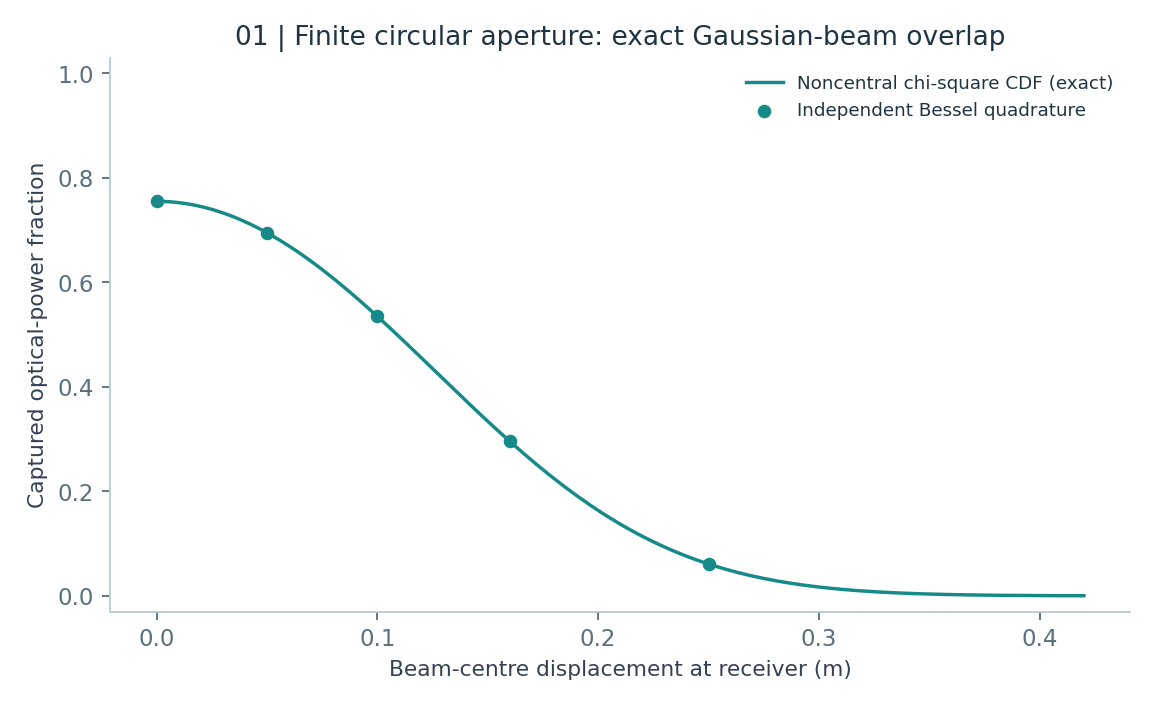

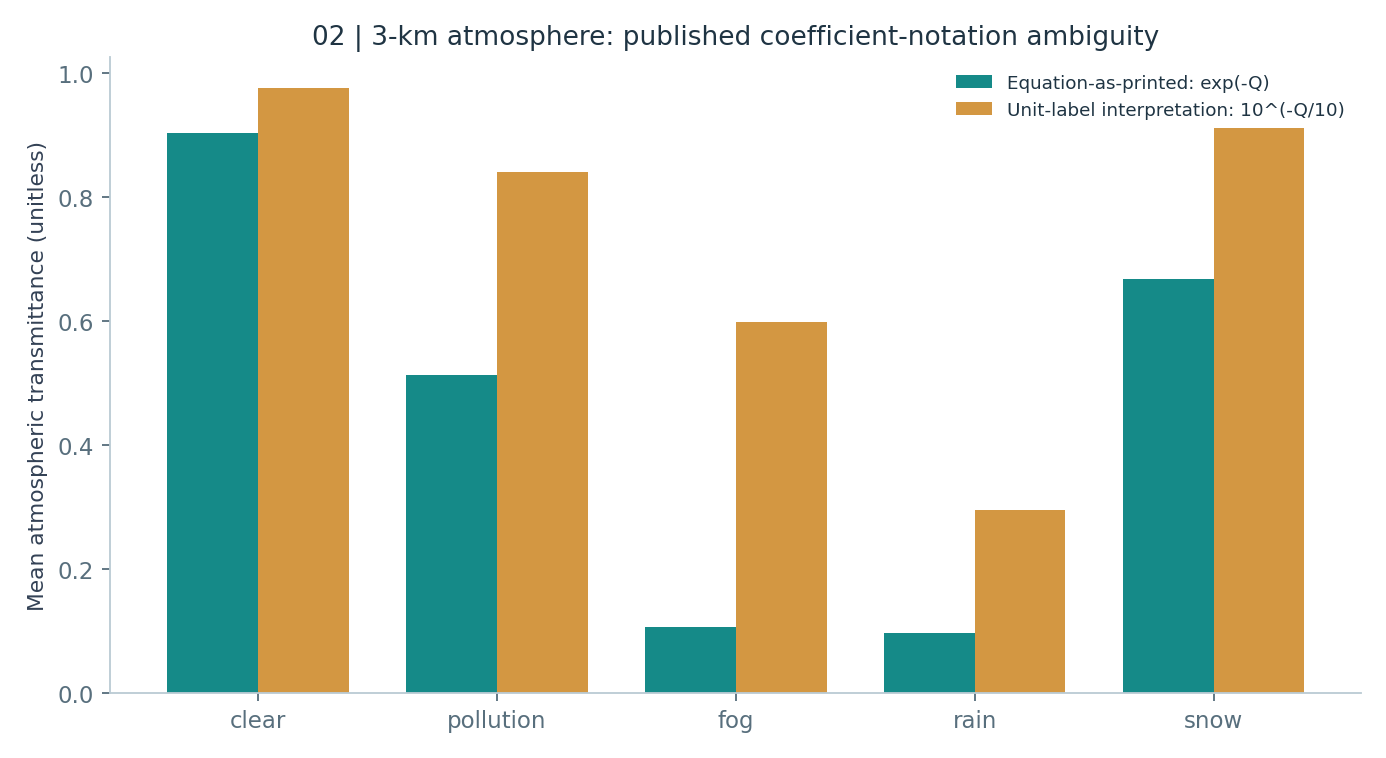

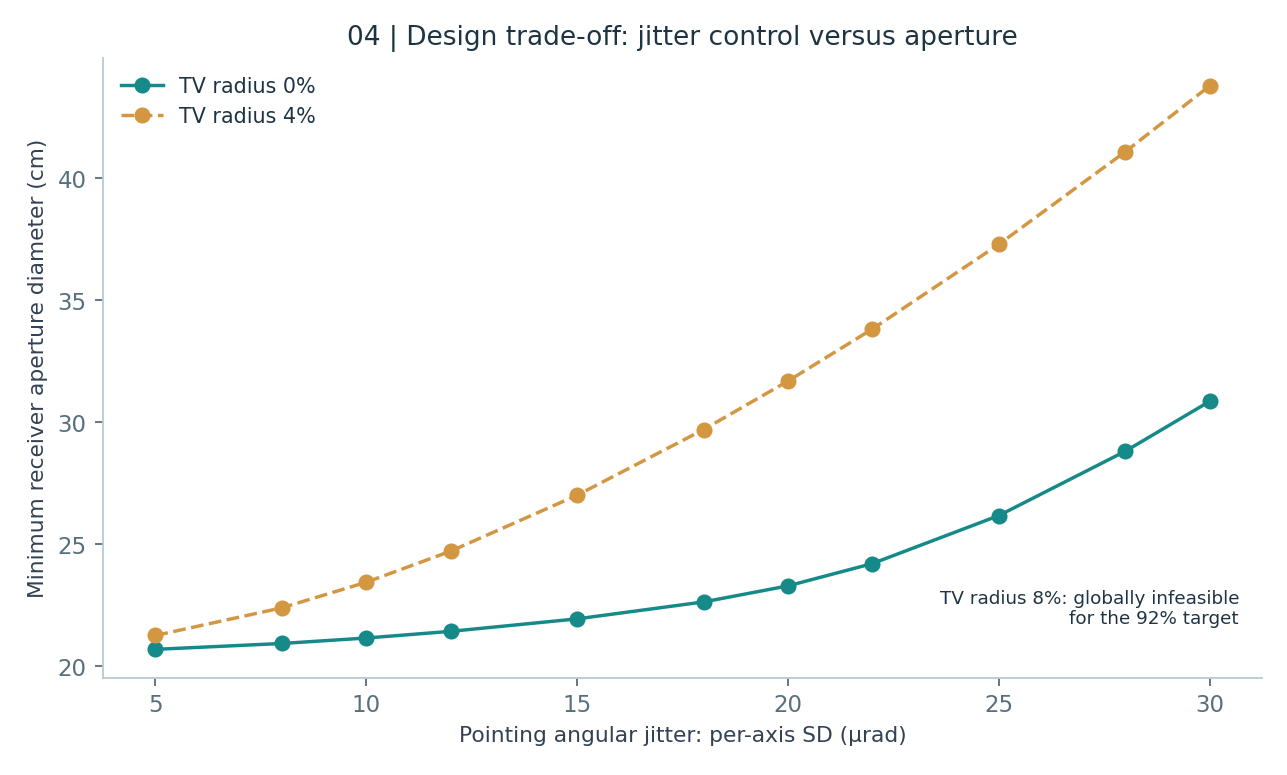

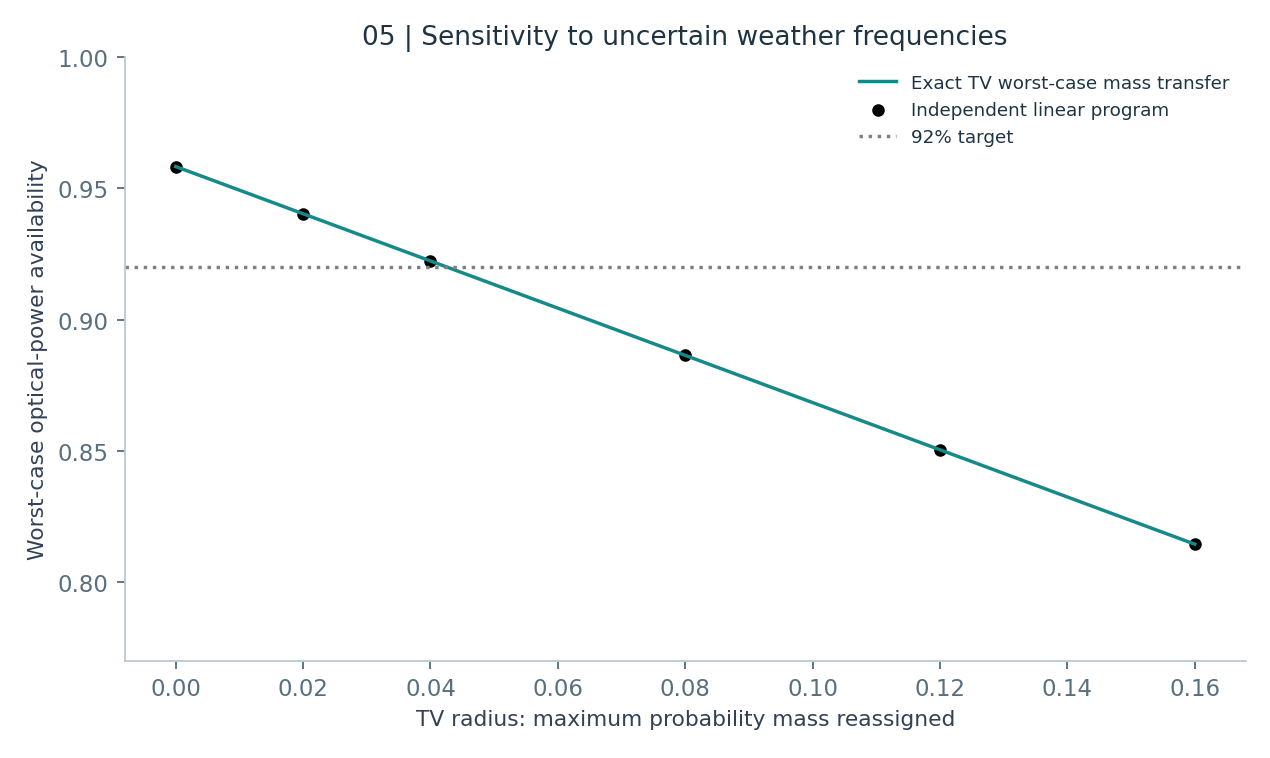

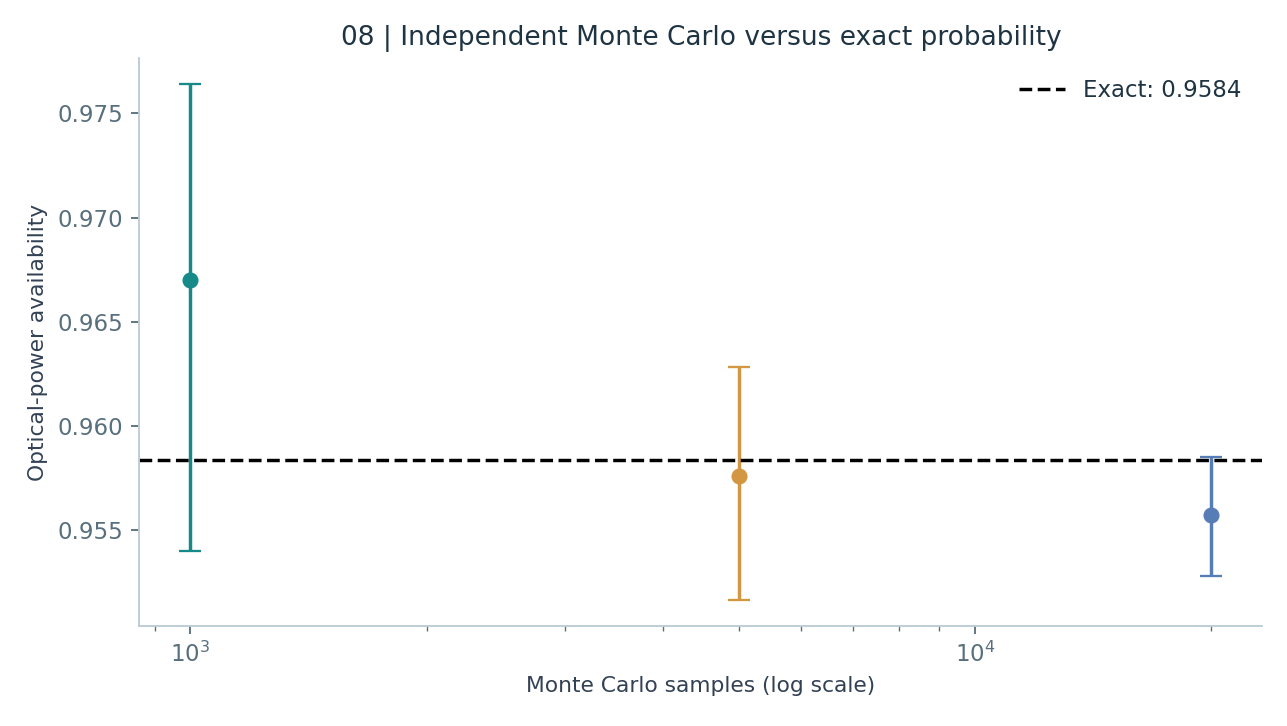

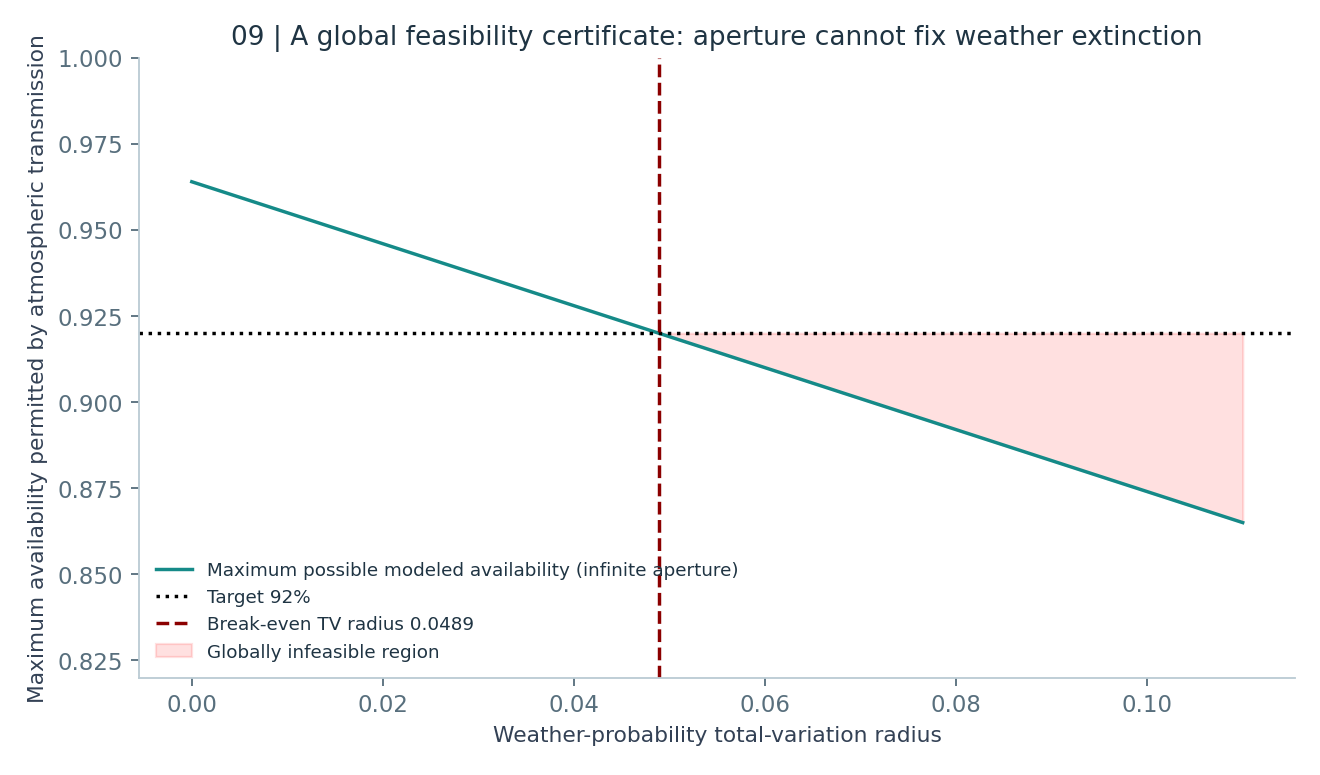

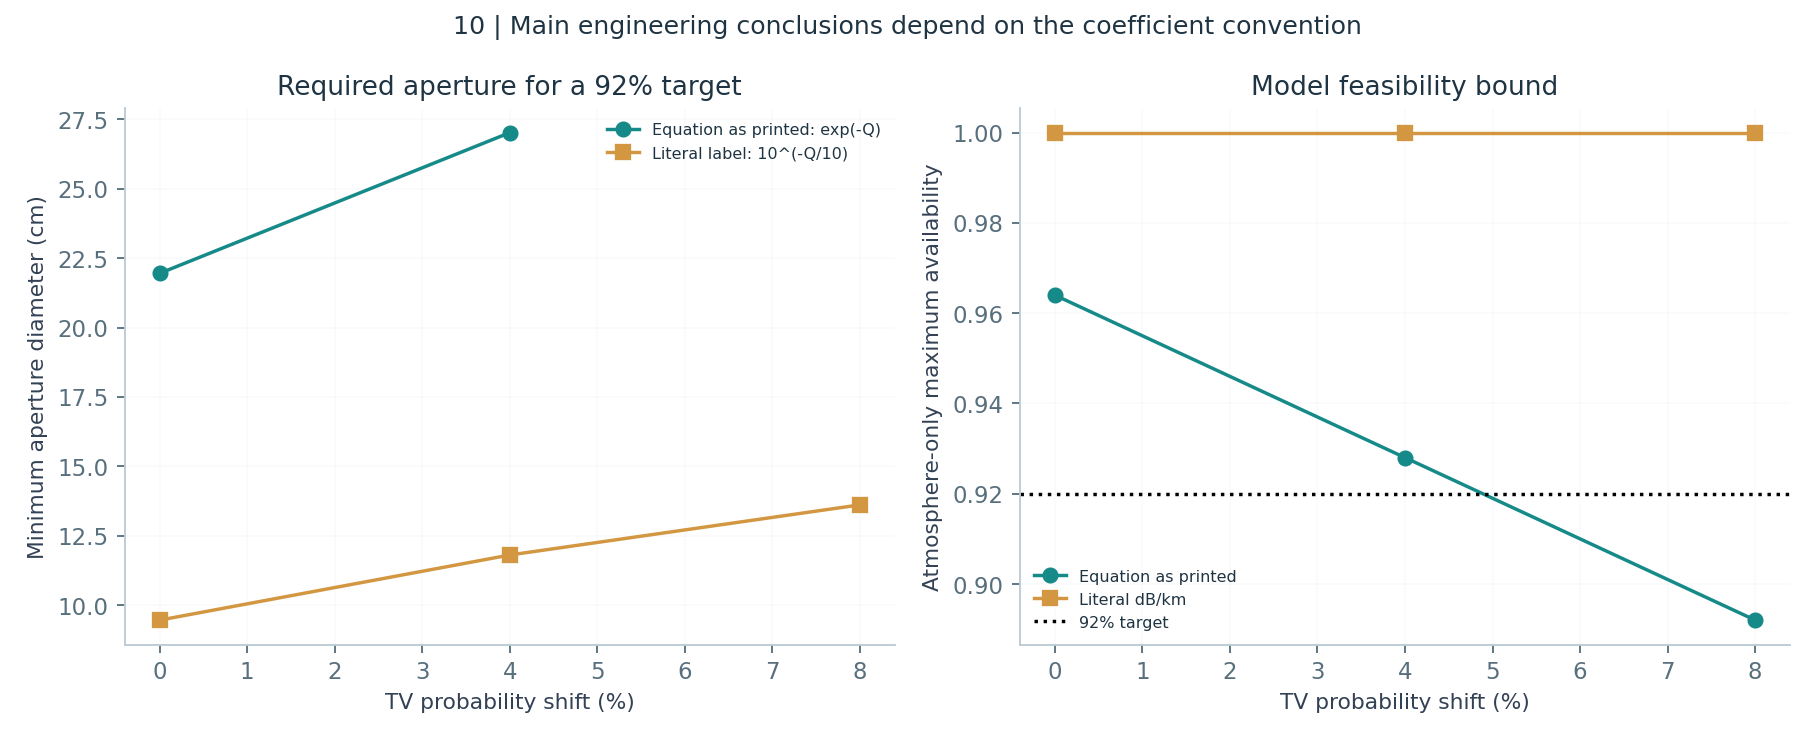

In [9]:
from IPython.display import display, Image
from pathlib import Path
for figure in ('01_aperture_integral_validation','02_atmospheric_unit_interpretations',
               '04_minimum_aperture_frontier','05_weather_probability_shift',
               '08_monte_carlo_validation','09_atmospheric_feasibility_ceiling',
               '10_optimization_convention_sensitivity'):
    display(Image(filename=f'results/figures/{figure}.png',width=680))


## 6. Interpretation and limitations

Under the **equation-as-printed** coefficient convention, the illustrative 3 km case with 15 µrad per-axis pointing jitter requires an aperture diameter of about 22 cm for the nominal scenario mixture and about 27 cm for a 4% total-variation uncertainty radius at a 92% target. Under the **literal dB/km** convention, the corresponding diameters are approximately 9.47 cm and 11.82 cm.

The atmospheric-only upper bound on achievable availability also depends on this convention: the 4.89% break-even uncertainty radius appears in the equation-as-printed case, but not in the literal dB/km case over the explored settings.

These are conditional model outputs, not receiver specifications or measured link-availability values. The weather mixture, transmitter power, receiver threshold, and pointing jitter are assumed. The model excludes turbulence, detector noise, time-varying weather, and pointing-control dynamics. Actual deployment conclusions would require calibrated atmospheric and receiver inputs.


## 7. Export results to upload directly to GitHub

The following cell produces `github_results_upload.zip`. It contains the top-level `results/` folder, including 10 PNG + SVG figure pairs, 8 CSV tables and complete run metadata. Extract it at the GitHub repository root or upload the folder contents directly. The notebook also displays output folder size and filenames. **Read the full-convention sensitivity (Figure 10) before reporting a design number.**


In [10]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
root = Path('results')
assert root.is_dir()
archive = Path('github_results_upload.zip')
with ZipFile(archive,'w',compression=ZIP_DEFLATED,compresslevel=8) as z:
    for p in sorted(root.rglob('*')):
        if p.is_file():
            z.write(p,p.as_posix())
print('Ready to upload:',archive.resolve())
print('ZIP size KB:',round(archive.stat().st_size/1024,1))
for p in sorted(root.rglob('*')):
    if p.is_file():print(f'{p.as_posix():70s} {p.stat().st_size/1024:8.1f} KB')
try:
    from google.colab import files
    files.download(str(archive))
except ImportError:
    print('Outside Colab: retrieve the ZIP from the working directory.')


Ready to upload: /mnt/data/nishat_showcase_notebook_check/github_results_upload.zip
ZIP size KB: 874.7
results/README.md                                                           2.6 KB
results/figures/01_aperture_integral_validation.png                        67.2 KB
results/figures/01_aperture_integral_validation.svg                        41.4 KB
results/figures/02_atmospheric_unit_interpretations.png                    55.0 KB
results/figures/02_atmospheric_unit_interpretations.svg                    39.9 KB
results/figures/03_availability_vs_aperture.png                           113.9 KB
results/figures/03_availability_vs_aperture.svg                            58.5 KB
results/figures/04_minimum_aperture_frontier.png                           85.5 KB
results/figures/04_minimum_aperture_frontier.svg                           45.7 KB
results/figures/05_weather_probability_shift.png                           82.2 KB
results/figures/05_weather_probability_shift.svg                   

## 8. Checks to understand before interpreting the results

The main mathematical checks are: (1) circular-aperture Gaussian capture and the noncentral chi-square CDF; (2) Rayleigh-distributed radial jitter arising from two independent Gaussian offsets; (3) exact probability calculations compared with Monte Carlo sampling; (4) total-variation worst-case probabilities compared with linear programming; and (5) how different coefficient-unit conventions change the design outcome.

The next useful investigation is not a longer simulation, but a site- and season-specific weather prior and receiver parameters backed by independent evidence.
